# Cuadratura adaptable de Simpson
### Algoritmo 4.3 de Burden — Métodos Numéricos II

**Tema:** integración numérica adaptativa  
**Ejemplo:** ilustración de Burden, página 167  
**Lenguaje:** Python (SymPy, NumPy y Matplotlib)

---

En este cuaderno se desarrolla el método, se programa el algoritmo y se verifica la aproximación con la integral exacta.

## 1. Planteamiento

Se desea aproximar la siguiente integral con una tolerancia de $10^{-4}$:

$$
I=\int_1^3\frac{100}{x^2}\sin\left(\frac{10}{x}\right)\,dx,
\qquad \mathrm{TOL}=10^{-4}.
$$

La función oscila y cambia de signo en el intervalo. Por ello conviene trabajar con subintervalos de diferente longitud, según lo necesite la aproximación.

## 2. Fórmulas del método

En un intervalo $[a,b]$, con $m=(a+b)/2$, la regla de Simpson es

$$
S(a,b)=\frac{b-a}{6}\left[f(a)+4f(m)+f(b)\right].
$$

Se vuelve a aplicar Simpson sobre $[a,m]$ y $[m,b]$ para obtener $S_1$ y $S_2$. La diferencia

$$
D=\left|S_1+S_2-S(a,b)\right|
$$

permite decidir si la aproximación es suficientemente buena.

El algoritmo 4.3 utiliza inicialmente $\tau=10\,\mathrm{TOL}$. Un intervalo se acepta cuando $D<\tau$; si no se cumple, se divide en dos y cada mitad recibe la tolerancia $\tau/2$. **Al aceptarlo se suma $S_1+S_2$**, sin agregar una corrección extra.

## 3. Función de prueba

Primero se define la función simbólica con SymPy. Después, `lambdify` la convierte en una función numérica que puede evaluarse rápidamente con NumPy.

In [1]:
import sympy as sp
import numpy as np
import matplotlib.pyplot as plt

x = sp.symbols("x", real=True)
f_simbolica = 100 * sp.sin(10/x) / x**2
f = sp.lambdify(x, f_simbolica, "numpy")

a, b = 1.0, 3.0
TOL = 1e-4
N = 15  # Número máximo de niveles permitido

print("Función:", f_simbolica)
print("Intervalo: [1, 3]")
print("Tolerancia:", TOL)

Función: 100*sin(10/x)/x**2
Intervalo: [1, 3]
Tolerancia: 0.0001


### Primera subdivisión

Antes de programar el procedimiento completo, se puede observar la decisión del primer paso. En este caso, el intervalo original no cumple la tolerancia y debe subdividirse.

In [2]:
h = (b-a) / 2
S = h * (f(a) + 4*f(a+h) + f(b)) / 3
S1 = h * (f(a) + 4*f(a+h/2) + f(a+h)) / 6
S2 = h * (f(a+h) + 4*f(a+3*h/2) + f(b)) / 6

D = abs(S1 + S2 - S)
print(f"Simpson inicial:   {S:.8f}")
print(f"Simpson refinado:  {S1 + S2:.8f}")
print(f"Diferencia:        {D:.8f}")
print(f"Tolerancia local:  {10*TOL:.8f}")
print("Decisión: subdividir" if D >= 10*TOL else "Decisión: aceptar")

Simpson inicial:   -50.80398679
Simpson refinado:  -14.39755533
Diferencia:        36.40643145
Tolerancia local:  0.00100000
Decisión: subdividir


## 4. Algoritmo 4.3 en Python

Para manejar los subintervalos pendientes se usa una **pila**. La instrucción `append()` guarda un subintervalo y `pop()` recupera el último. Se guarda la evaluación de la función en los nodos ya utilizados para no calcularla de nuevo.

En cada iteración:

1. Se calculan los dos nuevos puntos de evaluación y las dos reglas de Simpson.
2. Si la diferencia satisface la tolerancia local, se acepta el tramo.
3. En caso contrario, se guardan las mitades para revisarlas por separado.

La variable `nivel` controla que no se supere la profundidad permitida $N$.

In [3]:
def cuadratura_adaptable(funcion, a, b, tol=1e-4, N=15):
    """Regla de Simpson adaptable del algoritmo 4.3 de Burden."""
    if a >= b:
        raise ValueError("Se requiere a < b.")
    if tol <= 0 or N < 1:
        raise ValueError("La tolerancia y N deben ser positivos.")

    # Regla de Simpson para el intervalo completo.
    h = (b-a) / 2
    fa, fc, fb = funcion(a), funcion(a+h), funcion(b)
    evaluaciones = 3
    S = h * (fa + 4*fc + fb) / 3

    # Cada elemento conserva el tramo y sus datos de Simpson.
    # Se almacena primero la mitad derecha y luego la izquierda.
    pila = [(a, h, fa, fc, fb, S, 10*tol, 1)]
    aproximacion = 0.0
    aceptados = []

    while pila:
        ai, hi, FA, FC, FB, Si, tolerancia_local, nivel = pila.pop()

        # Solo se necesitan dos evaluaciones adicionales.
        FD = funcion(ai + hi/2)
        FE = funcion(ai + 3*hi/2)
        evaluaciones += 2

        S1 = hi * (FA + 4*FD + FC) / 6
        S2 = hi * (FC + 4*FE + FB) / 6
        diferencia = abs(S1 + S2 - Si)

        if diferencia < tolerancia_local:
            aproximacion += S1 + S2
            aceptados.append((ai, ai + 2*hi, nivel))
        else:
            if nivel >= N:
                raise RuntimeError("Se excedió el número máximo de niveles.")

            nueva_tolerancia = tolerancia_local / 2

            # La pila procesa primero la mitad izquierda.
            pila.append((ai+hi, hi/2, FC, FE, FB,
                         S2, nueva_tolerancia, nivel+1))
            pila.append((ai, hi/2, FA, FD, FC,
                         S1, nueva_tolerancia, nivel+1))

    return aproximacion, aceptados, evaluaciones

## 5. Aplicación al ejemplo del libro

Se ejecuta la función con los límites $a=1$, $b=3$ y la tolerancia solicitada. Además del valor de la integral, se revisa el número de tramos aceptados y las evaluaciones necesarias.

In [4]:
aproximacion, tramos, evaluaciones = cuadratura_adaptable(f, a, b, TOL, N)

print("RESULTADOS DE CUADRATURA ADAPTABLE")
print("-" * 40)
print(f"Integral aproximada:  {aproximacion:.10f}")
print(f"Tramos aceptados:     {len(tramos)}")
print(f"Evaluaciones de f:    {evaluaciones}")
print(f"Nivel máximo usado:   {max(t[2] for t in tramos)}")

# Valores reportados en la ilustración de Burden.
assert len(tramos) == 23
assert evaluaciones == 93
assert abs(aproximacion - (-1.426014)) < 1e-5

RESULTADOS DE CUADRATURA ADAPTABLE
----------------------------------------
Integral aproximada:  -1.4260148100
Tramos aceptados:     23
Evaluaciones de f:    93
Nivel máximo usado:   7


## 6. Verificación con SymPy

La integral también tiene solución exacta. En efecto,

$$
\frac{d}{dx}\left[10\cos\left(\frac{10}{x}\right)\right]
=\frac{100}{x^2}\sin\left(\frac{10}{x}\right).
$$

Por el teorema fundamental del cálculo,

$$
I=\left[10\cos\left(\frac{10}{x}\right)\right]_1^3
=10\left[\cos\left(\frac{10}{3}\right)-\cos(10)\right].
$$

El resultado exacto sirve para calcular el error real del método; durante la cuadratura adaptable no se necesita conocerlo.

In [5]:
integral_exacta = sp.integrate(f_simbolica, (x, 1, 3))
valor_exacto = float(sp.N(integral_exacta, 16))
error_absoluto = abs(valor_exacto - aproximacion)
error_relativo = 100 * error_absoluto / abs(valor_exacto)

print(f"Integral exacta:      {valor_exacto:.10f}")
print(f"Integral aproximada: {aproximacion:.10f}")
print(f"Error absoluto:      {error_absoluto:.10e}")
print(f"Error relativo:      {error_relativo:.6f} %")
print(f"¿Cumple tolerancia?: {error_absoluto < TOL}")

assert error_absoluto < TOL
assert abs(valor_exacto - 10*(np.cos(10/3)-np.cos(10))) < 1e-12

Integral exacta:      -1.4260247563
Integral aproximada: -1.4260148100
Error absoluto:      9.9462968184e-06
Error relativo:      0.000697 %
¿Cumple tolerancia?: True


## 7. Gráficas

En la primera gráfica se observa el comportamiento de la función en $[1,3]$. El relleno azul representa las áreas positivas y el naranja las negativas. La segunda muestra los **23 subintervalos finales** que eligió el algoritmo.

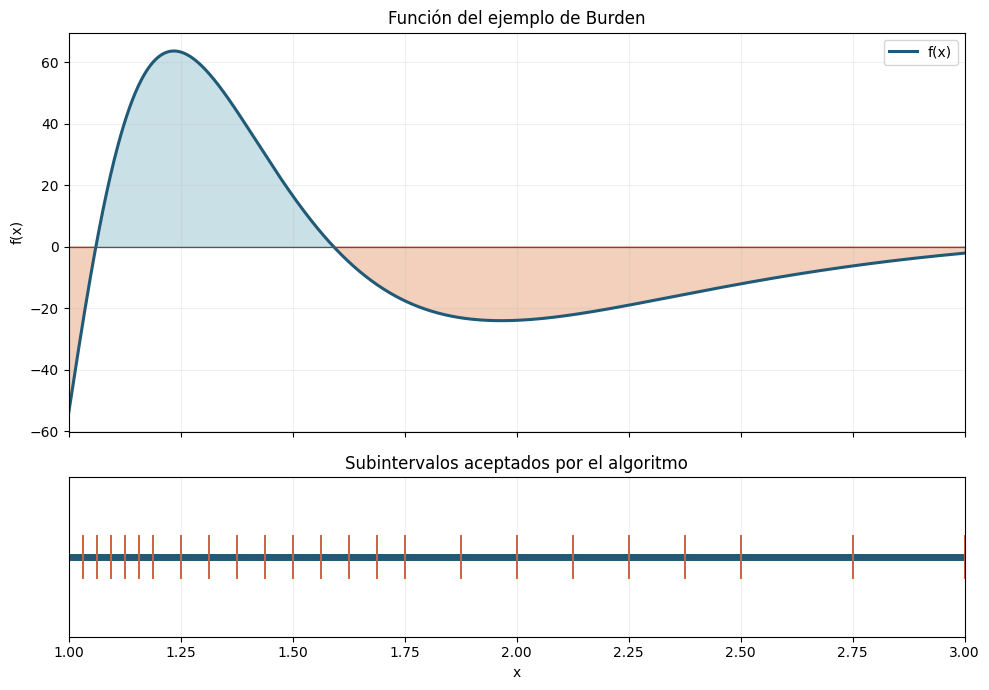

In [6]:
xx = np.linspace(a, b, 1200)
yy = f(xx)

fig, ejes = plt.subplots(2, 1, figsize=(10, 7), sharex=True,
                         gridspec_kw={"height_ratios": [3, 1.2]})

# Gráfica de la función.
ejes[0].plot(xx, yy, color="#205a77", linewidth=2.2, label="f(x)")
ejes[0].axhline(0, color="#555555", linewidth=0.9)
ejes[0].fill_between(xx, 0, yy, where=yy >= 0, color="#87bbc8", alpha=0.45)
ejes[0].fill_between(xx, 0, yy, where=yy < 0, color="#e9a27b", alpha=0.50)
ejes[0].set_title("Función del ejemplo de Burden")
ejes[0].set_ylabel("f(x)")
ejes[0].grid(alpha=0.18)
ejes[0].legend()

# Dibujar las longitudes de los tramos aceptados.
for izquierda, derecha, nivel in tramos:
    ejes[1].plot([izquierda, derecha], [1, 1], color="#205a77", lw=5)
    ejes[1].plot([izquierda, izquierda], [0.88, 1.12], color="#cc623e", lw=1.4)
ejes[1].plot([b, b], [0.88, 1.12], color="#cc623e", lw=1.4)
ejes[1].set_yticks([])
ejes[1].set_ylim(0.55, 1.45)
ejes[1].set_xlim(a, b)
ejes[1].set_title("Subintervalos aceptados por el algoritmo")
ejes[1].set_xlabel("x")
ejes[1].grid(axis="x", alpha=0.18)

plt.tight_layout()
plt.show()

### Registro de los subintervalos

La tabla permite ver que el ancho no es constante: el método realiza más subdivisiones en las zonas donde la curva exige mayor precisión.

In [7]:
print(f"{'Tramo':>5} {'a_i':>12} {'b_i':>12} {'Ancho':>12} {'Nivel':>7}")
print("-" * 54)
for i, (izquierda, derecha, nivel) in enumerate(tramos, 1):
    print(f"{i:5d} {izquierda:12.6f} {derecha:12.6f} "
          f"{derecha-izquierda:12.6f} {nivel:7d}")

Tramo          a_i          b_i        Ancho   Nivel
------------------------------------------------------
    1     1.000000     1.031250     0.031250       7
    2     1.031250     1.062500     0.031250       7
    3     1.062500     1.093750     0.031250       7
    4     1.093750     1.125000     0.031250       7
    5     1.125000     1.156250     0.031250       7
    6     1.156250     1.187500     0.031250       7
    7     1.187500     1.250000     0.062500       6
    8     1.250000     1.312500     0.062500       6
    9     1.312500     1.375000     0.062500       6
   10     1.375000     1.437500     0.062500       6
   11     1.437500     1.500000     0.062500       6
   12     1.500000     1.562500     0.062500       6
   13     1.562500     1.625000     0.062500       6
   14     1.625000     1.687500     0.062500       6
   15     1.687500     1.750000     0.062500       6
   16     1.750000     1.875000     0.125000       5
   17     1.875000     2.000000     0.125000

## 8. Resultado final

La aproximación por Simpson adaptable con $\mathrm{TOL}=10^{-4}$ es

$$
\boxed{I\approx -1.4260148100}
$$

Comparando con $I_{\mathrm{exacta}}\approx -1.4260247563$ se obtuvo

$$
\boxed{E_{\mathrm{abs}}\approx 9.9463\times 10^{-6}<10^{-4}}.
$$

Se utilizaron **23 subintervalos** y **93 evaluaciones de la función**, como en la ilustración del texto. El método concentra las subdivisiones donde la función cambia más rápidamente y evita usar un paso uniforme en todo el intervalo.

**Referencia:** R. L. Burden, J. D. Faires y A. M. Burden, *Análisis numérico*, 10.ª edición, sección 4.6, algoritmo 4.3 e ilustración (pp. 166–167).